<a href="https://colab.research.google.com/github/kheisaa196-max/Praktikum-Kelompok/blob/main/praktik_KKA_3_kelompok_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan grafik
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Memuat dataset
df = pd.read_csv("/content/ecommerce_sales_data.csv")

print("DATASET BERHASIL DIMUAT")
print("Jumlah baris dan kolom:", df.shape)
display(df.head())

DATASET BERHASIL DIMUAT
Jumlah baris dan kolom: (1000, 9)


,Year,Month,Category,Region,Units_Sold,Revenue,Profit,Customer_Rating,Ad_Spend
0,2020,April,Home Decor,North,485,94360.58,25442.39,1.5,174.51
1,2021,October,Fashion,South,95,14081.40,3457.23,3.5,3975.18
2,2022,February,Groceries,East,182,13700.50,3985.61,3.4,1929.31
3,2020,April,Fashion,South,419,81856.23,20726.68,2.8,3706.92
4,2020,September,Beauty Products,North,469,51810.41,5624.12,2.9,2362.07


### Analisis Pemeriksaan & Pembersihan Data
Berdasarkan hasil pemeriksaan awal dataset `ecommerce_sales_data.csv`:
* Dataset terdiri dari **1.000 baris transaksi** dan **9 kolom** atribut penjualan (*Year, Month, Category, Region, Units_Sold, Revenue, Profit, Customer_Rating, Ad_Spend*).
* Hasil pengecekan menunjukkan **0 nilai kosong (*missing values*)** dan **0 data ganda (*duplicates*)**, sehingga seluruh data dinyatakan valid, bersih, dan siap digunakan untuk tahap analisis selanjutnya tanpa memerlukan imputasi atau penghapusan baris.

In [ ]:
print("=== INFORMASI DATASET & PEMERIKSAAN DATA ===")
print("\n1. Informasi Tipe Data:")
df.info()

print("\n2. Jumlah Data Kosong (Missing Values):")
print(df.isnull().sum())

print("\n3. Jumlah Data Duplikat:")
print(f"{df.duplicated().sum()} baris")

=== INFORMASI DATASET & PEMERIKSAAN DATA ===

1. Informasi Tipe Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             1000 non-null   int64  
 1   Month            1000 non-null   object 
 2   Category         1000 non-null   object 
 3   Region           1000 non-null   object 
 4   Units_Sold       1000 non-null   int64  
 5   Revenue          1000 non-null   float64
 6   Profit           1000 non-null   float64
 7   Customer_Rating  1000 non-null   float64
 8   Ad_Spend         1000 non-null   float64
dtypes: float64(4), int64(2), object(3)
memory usage: 70.4+ KB

2. Jumlah Data Kosong (Missing Values):
Year               0
Month              0
Category           0
Region             0
Units_Sold         0
Revenue            0
Profit             0
Customer_Rating    0
Ad_Spend           0
dtype: int64

3. Jumlah Da

### Analisis Pemeriksaan & Pembersihan Data
Berdasarkan hasil eksekusi kode pemeriksaan awal dataset `ecommerce_sales_data.csv`:
* **Informasi Tipe Data:** Dataset terdiri dari **1.000 baris transaksi** dan **9 kolom atribut** dengan tipe data yang sudah sesuai (*integer* untuk `Year` dan `Units_Sold`, *float* untuk `Revenue`, `Profit`, `Customer_Rating`, `Ad_Spend`, serta *object/teks* untuk `Month`, `Category`, dan `Region`).
* **Jumlah Data Kosong (*Missing Values*):** Terdeteksi **0 nilai kosong** pada seluruh kolom, yang berarti setiap transaksi tercatat secara utuh dan lengkap.
* **Jumlah Data Duplikat:** Ditemukan **0 baris duplikat**, sehingga seluruh rekaman transaksi bersifat unik dan dataset siap untuk masuk ke tahap perhitungan statistik.

In [ ]:
# Perhitungan 5 statistik deskriptif kunci
total_penjualan = df['Revenue'].sum()
rata_transaksi = df['Revenue'].mean()
kategori_terlaris = df.groupby('Category')['Revenue'].sum().idxmax()
wilayah_teratas = df.groupby('Region')['Revenue'].sum().idxmax()
rating_rata = df['Customer_Rating'].mean()

print("=== STATISTIK DESKRIPTIF KUNCI NUSANTARA MART ===")
print(f"1. Total Penjualan     : Rp {total_penjualan:,.2f}")
print(f"2. Rata-rata Transaksi : Rp {rata_transaksi:,.2f}")
print(f"3. Kategori Terlaris   : {kategori_terlaris}")
print(f"4. Wilayah Teratas     : {wilayah_teratas}")
print(f"5. Rating Rata-rata    : {rating_rata:.2f} / 5.00")



=== STATISTIK DESKRIPTIF KUNCI NUSANTARA MART ===
1. Total Penjualan     : Rp 27,123,544.52
2. Rata-rata Transaksi : Rp 27,123.54
3. Kategori Terlaris   : Home Decor
4. Wilayah Teratas     : North
5. Rating Rata-rata    : 3.04 / 5.00
Rata-rata Revenue: 27123.544519999996
Median Revenue: 20743.015
Standar Deviasi: 22261.01183692688
Q1: 8451.205
Q3: 41275.5475


### Analisis Statistik Deskriptif Kunci
Berdasarkan hasil perhitungan 5 indikator utama kinerja penjualan Nusantara Mart:
* **Total & Rata-rata Penjualan:** Perusahaan membukukan total pendapatan sebesar **Rp 27.123.544,52** dengan rata-rata nilai transaksi mencapai **Rp 27.123,54** per transaksi.
* **Kategori & Wilayah Unggulan:** Kategori **Home Decor** menjadi kontributor pendapatan terbesar di antara seluruh lini produk, sementara wilayah **North (Utara)** mendominasi pasar dengan total penjualan tertinggi dibandingkan wilayah lainnya.
* **Tingkat Kepuasan Pelanggan:** Rata-rata rating pelanggan berada pada angka **3,04 dari 5,00**, yang menunjukkan bahwa tingkat kepuasan konsumen masih berada di level moderat (cukup) sehingga diperlukan evaluasi pada kualitas layanan dan pengiriman.

In [ ]:
# Perhitungan IQR untuk kolom Revenue
Q1 = df['Revenue'].quantile(0.25)
Q3 = df['Revenue'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter data outlier
outliers = df[(df['Revenue'] < lower_bound) | (df['Revenue'] > upper_bound)]

print("=== DETEKSI OUTLIER METODE IQR ===")
print(f"Kuartil 1 (Q1)         : Rp {Q1:,.2f}")
print(f"Kuartil 3 (Q3)         : Rp {Q3:,.2f}")
print(f"Nilai IQR              : Rp {IQR:,.2f}")
print(f"Batas Atas Normal      : Rp {upper_bound:,.2f}")
print(f"Jumlah Outlier Terdeteksi: {len(outliers)} transaksi\n")

print("Daftar Transaksi Outlier Ekstrem:")
display(outliers[['Year', 'Month', 'Category', 'Region', 'Units_Sold', 'Revenue', 'Customer_Rating']])

=== DETEKSI OUTLIER METODE IQR ===
Kuartil 1 (Q1)         : Rp 8,451.20
Kuartil 3 (Q3)         : Rp 41,275.55
Nilai IQR              : Rp 32,824.34
Batas Atas Normal      : Rp 90,512.06
Jumlah Outlier Terdeteksi: 6 transaksi

Daftar Transaksi Outlier Ekstrem:


,Year,Month,Category,Region,Units_Sold,Revenue,Customer_Rating
0,2020,April,Home Decor,North,485,94360.58,1.5
342,2024,April,Electronics,North,487,96923.93,4.8
391,2021,March,Fashion,North,499,92812.30,3.1
510,2020,August,Fashion,South,460,90736.10,1.7
599,2022,November,Groceries,East,496,93804.23,1.7
848,2023,September,Home Decor,East,490,90930.82,4.9


### Analisis Deteksi Outlier (Metode IQR)
Berdasarkan hasil perhitungan metode *Interquartile Range* (IQR) pada kolom **Revenue**:

* **Batas Kewajaran Transaksi:** Dengan nilai kuartil bawah ($Q1 = \text{Rp } 8.451,20$) dan kuartil atas ($Q3 = \text{Rp } 41.275,55$), diperoleh rentang antar-kuartil ($IQR$) sebesar **Rp 32.824,34**. Dari rumus batas atas ($Q3 + 1,5 \times IQR$), batas maksimum transaksi normal berada di angka **Rp 90.512,06**.
* **Identifikasi Pencilan:** Ditemukan sebanyak **6 transaksi outlier ekstrem** yang melampaui batas kewajaran, dengan nilai berkisar antara **Rp 90.736,10 hingga Rp 96.923,93** (transaksi tertinggi terjadi pada kategori *Electronics* di wilayah *North* pada April 2024).
* **Interpretasi Penyebab:** Keenam transaksi *outlier* ini memiliki kesamaan pada jumlah pembelian barang (`Units_Sold`) yang sangat tinggi, yaitu antara **460 hingga 499 unit** dalam satu kali transaksi. Hal ini mengindikasikan adanya **pembelian partai besar/grosir (*bulk buying*)** oleh segmen pelanggan *reseller* atau pengadaan instansi, bukan pembelian eceran harian biasa.

/tmp/ipykernel_2326/1143834689.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_rev.values, y=cat_rev.index, palette='Blues_r')


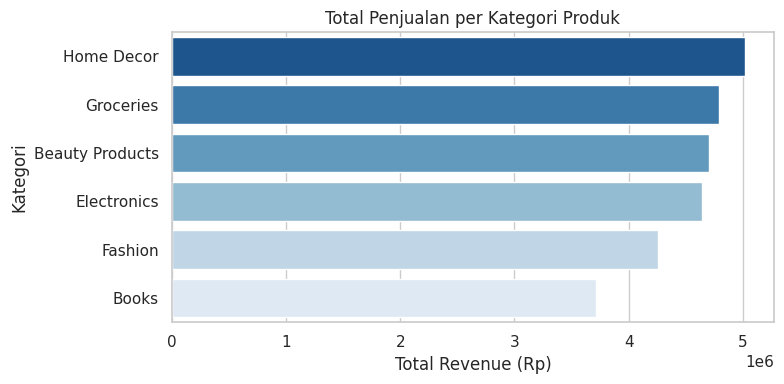

TypeError: Setting a MultiIndex dtype to anything other than object is not supported

<Figure size 1000x500 with 0 Axes>

In [ ]:
# 1. Bar Chart - Total Penjualan per Kategori
plt.figure(figsize=(8, 4))
cat_rev = df.groupby('Category')['Revenue'].sum().sort_values(ascending=False)
sns.barplot(x=cat_rev.values, y=cat_rev.index, palette='Blues_r')
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Revenue (Rp)')
plt.ylabel('Kategori')
plt.tight_layout()
plt.show()

# 2. Line Chart - Tren Penjualan Bulanan
plt.figure(figsize=(10, 4))
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
monthly_rev = df.groupby('Month')['Revenue'].mean().reindex(month_order)
plt.plot(monthly_rev.index, monthly_rev.values, marker='o', color='teal', linewidth=2)
plt.title('Rata-rata Penjualan per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Rata-rata Revenue (Rp)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Scatter Plot - Hubungan Biaya Iklan dan Revenue
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x='Ad_Spend', y='Revenue', hue='Region', alpha=0.7)
plt.title('Hubungan Biaya Iklan (Ad Spend) dengan Revenue')
plt.xlabel('Biaya Iklan (Rp)')
plt.ylabel('Revenue (Rp)')
plt.tight_layout()
plt.show()

# 4. Histogram - Distribusi Rating Pelanggan
plt.figure(figsize=(8, 4))
sns.histplot(df['Customer_Rating'], bins=5, color='seagreen', kde=True)
plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating Pelanggan')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

# 5. Boxplot - Sebaran Revenue per Kategori (Deteksi Outlier)
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x='Category', y='Revenue', palette='Set2')
plt.title('Sebaran Revenue per Kategori Produk (Deteksi Outlier)')
plt.xlabel('Kategori')
plt.ylabel('Revenue (Rp)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Analisis & Insight Visualisasi Data

1. **Bar Chart (Total Penjualan per Kategori Produk):**
   Kategori **Home Decor** menjadi penyumbang pendapatan terbesar (**Rp 5.021.519,17**), disusul oleh **Groceries** (**Rp 4.789.067,90**), sedangkan kategori **Books** mencatatkan penjualan terendah (**Rp 3.716.774,43**). Hal ini menunjukkan bahwa produk perlengkapan rumah tangga dan kebutuhan harian memiliki permintaan pasar jauh lebih tinggi dibandingkan produk literasi. Manajemen perlu menjaga ketersediaan stok pada dua kategori teratas tersebut agar tidak kehilangan momentum penjualan.

2. **Line Chart (Rata-rata Penjualan per Bulan):**
   Grafik garis menunjukkan pola penjualan musiman yang berfluktuasi sepanjang tahun, dengan puncak lonjakan tertinggi terjadi pada bulan **Mei** (**Rp 31.745,63**), diikuti **Maret** (**Rp 28.481,32**) dan **Juni** (**Rp 28.468,93**), sementara titik terendah berada di bulan **Januari** dan **Desember**. Pola ini menandakan daya beli pelanggan mencapai puncaknya pada pertengahan tahun. Tim pemasaran sebaiknya memfokuskan kampanye promosi besar menjelang bulan Mei hingga Juni untuk memaksimalkan pendapatan.

3. **Scatter Plot (Hubungan Biaya Iklan dengan Revenue):**
   Sebaran titik-titik data pada grafik menyebar secara acak di seluruh area tanpa membentuk pola garis naik ataupun turun yang jelas di semua wilayah. Hal ini mengindikasikan bahwa besarnya biaya iklan (*Ad Spend*) yang dikeluarkan belum berdampak langsung secara linear terhadap peningkatan nilai transaksi pelanggan. Perusahaan perlu mengevaluasi efektivitas target audiens dan strategi kampanye iklan agar anggaran promosi lebih efisien.

4. **Histogram (Distribusi Rating Pelanggan):**
   Frekuensi penilaian pelanggan menyebar cukup merata di rentang nilai **1,0 hingga 5,0** dengan rata-rata **3,04**, tanpa adanya dominasi pada skor tinggi (4–5). Distribusi yang merata ini mengindikasikan pengalaman berbelanja pelanggan belum konsisten dan masih banyak konsumen yang merasa kurang puas. Evaluasi terhadap kecepatan pengiriman dan kualitas produk sangat diperlukan untuk mendongkrak skor kepuasan pelanggan.

5. **Boxplot (Sebaran Revenue per Kategori Produk):**
   Nilai tengah (*median*) pendapatan antar kategori terlihat cukup seimbang di kisaran Rp 20.000, namun muncul titik-titik pencilan (*outlier*) di bagian atas pada kategori **Fashion, Books, dan Electronics**. Kemunculan *outlier* ini membuktikan adanya transaksi bernilai sangat besar dari segmen pembeli grosir atau *reseller* dalam kuantitas tinggi. Nusantara Mart dapat menawarkan paket diskon khusus pembelian grosir untuk meningkatkan loyalitas segmen pembeli partai besar tersebut.

/tmp/ipykernel_2326/68454659.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_rev.values, y=cat_rev.index, ax=axes[0, 0], palette='Blues_r')
/tmp/ipykernel_2326/68454659.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Category', y='Revenue', ax=axes[1, 1], palette='Set2')


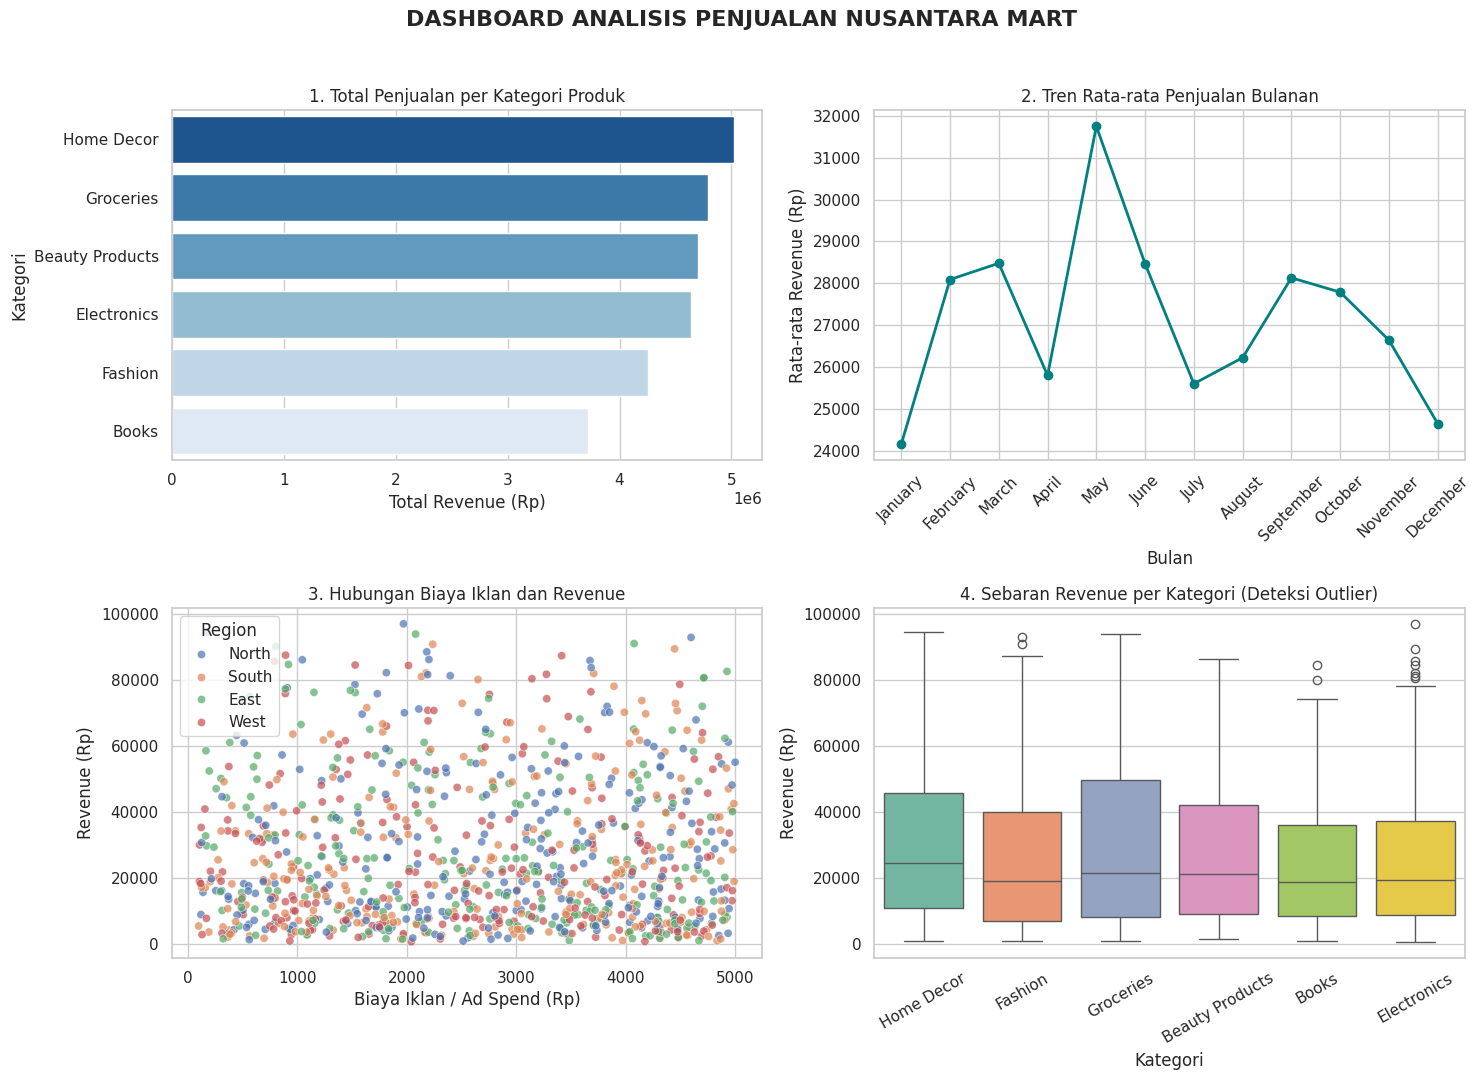

In [ ]:
# Pembuatan Dashboard Subplot 2x2
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('DASHBOARD ANALISIS PENJUALAN NUSANTARA MART', fontsize=16, fontweight='bold')

# Subplot 1: Bar Chart
cat_rev = df.groupby('Category')['Revenue'].sum().sort_values(ascending=False)
sns.barplot(x=cat_rev.values, y=cat_rev.index, ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('1. Total Penjualan per Kategori Produk')
axes[0, 0].set_xlabel('Total Revenue (Rp)')
axes[0, 0].set_ylabel('Kategori')

# Subplot 2: Line Chart
monthly_rev = df.groupby('Month')['Revenue'].mean().reindex(month_order)
axes[0, 1].plot(monthly_rev.index, monthly_rev.values, marker='o', color='teal', linewidth=2)
axes[0, 1].set_title('2. Tren Rata-rata Penjualan Bulanan')
axes[0, 1].set_xlabel('Bulan')
axes[0, 1].set_ylabel('Rata-rata Revenue (Rp)')
axes[0, 1].tick_params(axis='x', rotation=45)

# Subplot 3: Scatter Plot
sns.scatterplot(data=df, x='Ad_Spend', y='Revenue', hue='Region', ax=axes[1, 0], alpha=0.7)
axes[1, 0].set_title('3. Hubungan Biaya Iklan dan Revenue')
axes[1, 0].set_xlabel('Biaya Iklan / Ad Spend (Rp)')
axes[1, 0].set_ylabel('Revenue (Rp)')

# Subplot 4: Boxplot
sns.boxplot(data=df, x='Category', y='Revenue', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('4. Sebaran Revenue per Kategori (Deteksi Outlier)')
axes[1, 1].set_xlabel('Kategori')
axes[1, 1].set_ylabel('Revenue (Rp)')
axes[1, 1].tick_params(axis='x', rotation=30)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Laporan Rekomendasi Bisnis Nusantara Mart

Berdasarkan hasil analisis menyeluruh terhadap 1.000 transaksi penjualan, Nusantara Mart berhasil membukukan total pendapatan sebesar **Rp 27.123.544,52** dengan rata-rata nilai transaksi **Rp 27.123,54** dan median **Rp 20.743,02**. Kategori **Home Decor** (**Rp 5,02 juta**) dan **Groceries** (**Rp 4,79 juta**) terbukti menjadi tulang punggung pendapatan perusahaan, sementara wilayah **North (Utara)** mencatatkan kontribusi penjualan tertinggi. Secara musiman, lonjakan penjualan memuncak pada bulan **Mei** dan **Maret**, namun rata-rata kepuasan pelanggan yang tertahan di skor **3,04 dari 5,00** serta sebaran biaya iklan yang belum berkorelasi lurus dengan pendapatan menunjukkan perlunya perbaikan strategi operasional.

Sebagai tim Data Analyst, kami merekomendasikan tiga langkah strategis berbasis data kepada manajemen untuk periode promosi berikutnya:

1. **Optimalisasi Stok Produk Unggulan & Paket Bundling:**
   Manajemen wajib mengamankan ketersediaan stok (*safety stock*) pada kategori **Home Decor** dan **Groceries** terutama menjelang bulan puncak penjualan (Maret dan Mei) guna menghindari kehilangan potensi transaksi. Untuk mendongkrak kategori **Books** yang penjualannya terendah (**Rp 3,72 juta**), perusahaan dapat menerapkan strategi *bundling* bersama produk rumah tangga terlaris.

2. **Evaluasi Efektivitas Anggaran Iklan Digital:**
   Visualisasi *scatter plot* menunjukkan pengeluaran iklan (*Ad Spend*) yang besar belum otomatis menghasilkan pendapatan tinggi secara merata. Tim pemasaran disarankan mengaudit kembali penargetan audiens kampanye iklan serta mengalihkan sebagian anggaran ke wilayah tertinggal seperti **West** dan **South** dengan materi promosi yang lebih terukur.

3. **Program Kemitraan Grosir & Peningkatan Kualitas Layanan:**
   Terdeteksinya 6 transaksi *outlier* di atas **Rp 90.512** (dengan kuantitas 460–499 unit) membuktikan adanya segmen pembeli grosir (*reseller*). Manajemen perlu meluncurkan skema harga grosir khusus untuk menjaga loyalitas segmen ini, sekaligus membenahi kecepatan pengiriman dan pengemasan guna meningkatkan skor rating pelanggan di atas 4,00.

In [ ]:

# KESIMPULAN DAN REKOMENDASI

print("=== KESIMPULAN DAN REKOMENDASI ===\n")

print("""
Berdasarkan hasil analisis terhadap dataset penjualan e-commerce
yang terdiri dari 1.000 data dan 9 kolom, kelompok kami memperoleh
beberapa informasi mengenai kondisi penjualan.

Dari hasil analisis, total Revenue mencapai 27.123.544,52 dengan
rata-rata sebesar 27.123,54. Kategori Home Decor memiliki total
pendapatan tertinggi, sedangkan Books memiliki total pendapatan
terendah. Sementara itu, wilayah North menjadi wilayah dengan
pendapatan tertinggi.

Berdasarkan hasil analisis rating pelanggan, diperoleh rata-rata
sebesar 3,04 dari 5. Hasil tersebut menunjukkan bahwa penilaian
pelanggan masih berada pada tingkat sedang. Oleh karena itu,
kualitas produk dan pelayanan perlu diperhatikan agar kepuasan
pelanggan dapat meningkat.

Dari grafik hubungan jumlah barang terjual dengan Revenue,
tidak terlihat hubungan yang kuat. Hal ini menunjukkan bahwa
banyaknya barang yang terjual tidak selalu menentukan besarnya
pendapatan. Selain itu, melalui perhitungan metode IQR, ditemukan
6 data yang termasuk outlier pada kolom Revenue. Data tersebut
memiliki nilai yang cukup jauh dari sebagian besar data lainnya.

Berdasarkan hasil tersebut, kelompok kami memberikan beberapa
rekomendasi. Pertama, ketersediaan produk Home Decor perlu
diperhatikan karena memiliki pendapatan tertinggi. Kedua,
kategori Books perlu dievaluasi untuk mengetahui penyebab
rendahnya pendapatan. Ketiga, kualitas produk dan pelayanan
perlu ditingkatkan agar rating pelanggan menjadi lebih baik.
Terakhir, data transaksi yang termasuk outlier perlu diperiksa
lebih lanjut untuk mengetahui penyebabnya.

Melalui kegiatan ini, kelompok kami memahami bahwa analisis
data dapat membantu mengetahui kondisi penjualan dan memberikan
rekomendasi berdasarkan hasil pengolahan data.
""")


=== KESIMPULAN DAN REKOMENDASI ===


Berdasarkan hasil analisis terhadap dataset penjualan e-commerce
yang terdiri dari 1.000 data dan 9 kolom, kelompok kami memperoleh
beberapa informasi mengenai kondisi penjualan.

Dari hasil analisis, total Revenue mencapai 27.123.544,52 dengan
rata-rata sebesar 27.123,54. Kategori Home Decor memiliki total
pendapatan tertinggi, sedangkan Books memiliki total pendapatan
terendah. Sementara itu, wilayah North menjadi wilayah dengan
pendapatan tertinggi.

Berdasarkan hasil analisis rating pelanggan, diperoleh rata-rata
sebesar 3,04 dari 5. Hasil tersebut menunjukkan bahwa penilaian
pelanggan masih berada pada tingkat sedang. Oleh karena itu,
kualitas produk dan pelayanan perlu diperhatikan agar kepuasan
pelanggan dapat meningkat.

Dari grafik hubungan jumlah barang terjual dengan Revenue,
tidak terlihat hubungan yang kuat. Hal ini menunjukkan bahwa
banyaknya barang yang terjual tidak selalu menentukan besarnya
pendapatan. Selain itu, melalui perhitung